# Data analysis
- Imports homeostatic data from '241007_Control_homeo_fusedV4.csv'
- Produces csv files used for analysis

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")

import clones


plt.rcParams['figure.figsize'] = (4, 3)


def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)
    

def laggedevent(movebytimeclone, dBas1, dSup1, dBas2, dSup2):
    ntimes  = np.shape(movebytimeclone)[1]
    nclones = np.shape(movebytimeclone)[0]
    
    event = np.zeros((ntimes - 2, ntimes - 1), dtype = 'int32')

    for t in range(ntimes - 1):
        for c in range(nclones):
            for n in range(1,ntimes - 1):
                if t + n < ntimes:
                    event[n-1, t] += (movebytimeclone[c, t, dBas1, dSup1] == 1) and (movebytimeclone[c, t+n, dBas2, dSup2] == 1)
    return event

def evenbias(clonesize, singletime = False):
    #Mathematica:  p = 1/m; Simplify[Sum[p*(1 - p)^(2*k - 1), {k, 1, Infinity}]]
    #We need a way of assessing the error on even bias
    
    if singletime == True:
        clonesize = np.array(clonesize[np.array(clonesize) > 0])
        fracEven = 1 - np.mean(clonesize % 2) 
        avSize    = np.mean(clonesize)
        fracexpect  = (avSize - 1)/(2*avSize - 1)
        
        return (fracEven - fracexpect)/(1 - fracexpect)
    else:
        clonesize = [np.array(cst[np.array(cst) > 0]) for cst in clonesize]
        avSize = np.array([np.mean(cst) for cst in clonesize])
        fracEven = np.array([1 - np.mean(cst % 2) for cst in clonesize])
        
    fracexpect  = (avSize - 1)/(2*(avSize) - 1)
    return (fracEven - fracexpect)/(1 - fracexpect)


'''  
    Compute the counts tensor for experiments
'''

def extend_livesize(livesize):
    nclones = np.shape(livesize)[0]
    time0 = np.zeros((nclones, 1, 2), dtype = 'int32')
    time0[:,0,0] = 1
    return np.concatenate((time0, livesize), axis = 1)



def get_allmoves(livesize, full_timelapse, use_df = False):
    ''' 
        Define allmoves in the following way:
        allmoves[time, bas_t-1, sup_t-1, bast, bast, dSup2, mouse, clone type]
        
        We only specify moves starting from surviving clone numbers
        
        This is convenient for specifying likelihood
        
        Then we specify the unique transitions which occur in the data
    '''
    
    full_livesize = extend_livesize(livesize)

    
    full_timelapse['max_tot'] = np.max(np.sum(full_livesize,2),1)
    
    full_timelapse['ctype'] = ''
    full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
    full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
    full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'
    
    mice = full_timelapse['mice_ID'].unique()
    max_bas = full_livesize[:,:,0].max() + 1
    max_sup = full_livesize[:,:,1].max() + 1
    
    ntimes = np.shape(full_livesize)[1] - 1
    
    ctypes = ['S', 'T', 'D']
    ntypes  = len(ctypes)
   
    allmoves = np.zeros((ntimes, max_bas, max_sup, max_bas, max_sup, ntypes, len(mice)), dtype = 'int32')

    for m in range(len(mice)):
        for ct in range(len(ctypes)):
            cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
            for c in range(len(cids)):
                for t in range(ntimes):
                    bas0 = full_livesize[cids[c],t,0]
                    sup0 = full_livesize[cids[c],t,1]
                    bas1 = full_livesize[cids[c],t+1,0]
                    sup1 = full_livesize[cids[c],t+1,1]
                    if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:
                        allmoves[t, bas0, sup0, bas1, sup1, ct, m] += 1
            
    allmoves_bas = np.sum(allmoves, axis = (2,4))
             
    if use_df:
        all_moves     = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'supra0', 'basal1', 'supra1', 'count'])
        all_moves_bas = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'basal1', 'count'])

        for m in range(len(mice)):
            for ct in range(len(ctypes)):
                cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
                for t in range(ntimes):
                    unqclones = np.unique(full_livesize[cids,t:t+2,:], axis = 0)
                    for u in unqclones:
                        bas0 = u[0,0]
                        sup0 = u[0,1]
                        bas1 = u[1,0]
                        sup1 = u[1,1]
                        if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'supra0': sup0, 'basal1': bas1, 'supra1': sup1, 'count': allmoves[t, bas0, sup0, bas1, sup1, ct, m]}
                            all_moves = pd.concat([all_moves, pd.DataFrame([to_append])], ignore_index=True)  
                            
                    unqbas = np.unique(full_livesize[cids,t:t+2,0], axis = 0)
                    for u in unqbas:
                        bas0 = u[0]
                        bas1 = u[1]
                        if bas0 > 0 and bas1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'basal1': bas1, 'count': allmoves_bas[t, bas0, bas1, ct, m]}
                            all_moves_bas = pd.concat([all_moves_bas, pd.DataFrame([to_append])], ignore_index=True)              
        
        return all_moves, all_moves_bas
    else:
        return allmoves, allmoves_bas
        


import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)

/tmp/ipykernel_176186/2106463435.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  full_timelapse.fillna(miss_flag, inplace=True)


Repairing basal CS mistakes for [481 505]
[[[0 5 6 4 3 5 4 5]
  [1 1 3 4 2 3 1 2]]

 [[1 0 0 0 1 0 0 0]
  [0 0 0 0 0 0 0 0]]]
Repairing total CS mistakes for [447 505]
[[[   2    4    1    0    0    0    0    0]
  [   0    2    2    1    0    4    0    0]]

 [[   1    0    0 -100    1    0    0    0]
  [   0    0    0 -100    0    0    0    0]]]
Repairing basal CS mistakes for [481 505]
[[[0 5 6 4 3 5 4 5]
  [1 1 3 4 2 3 1 2]]

 [[1 0 0 0 1 0 0 0]
  [0 0 0 0 0 0 0 0]]]
Repairing total CS mistakes for [447 505]
[[[   2    4    1    0    0    0    0    0]
  [   0    2    2    1    0    4    0    0]]

 [[   1    0    0 -100    1    0    0    0]
  [   0    0    0 -100    0    0    0    0]]]
Saved to: data_ctr.pkl


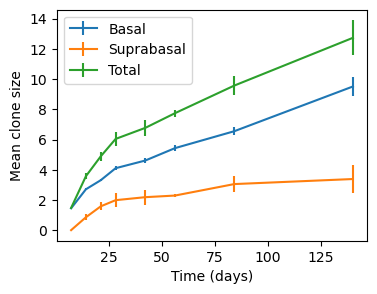

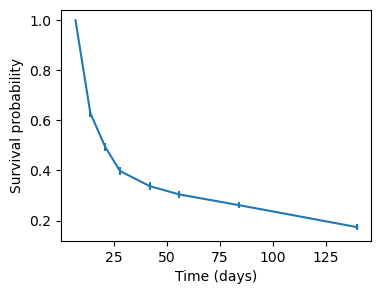

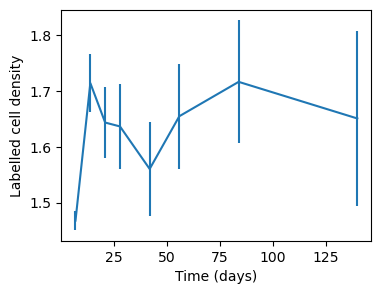

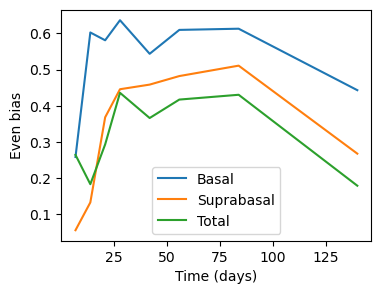

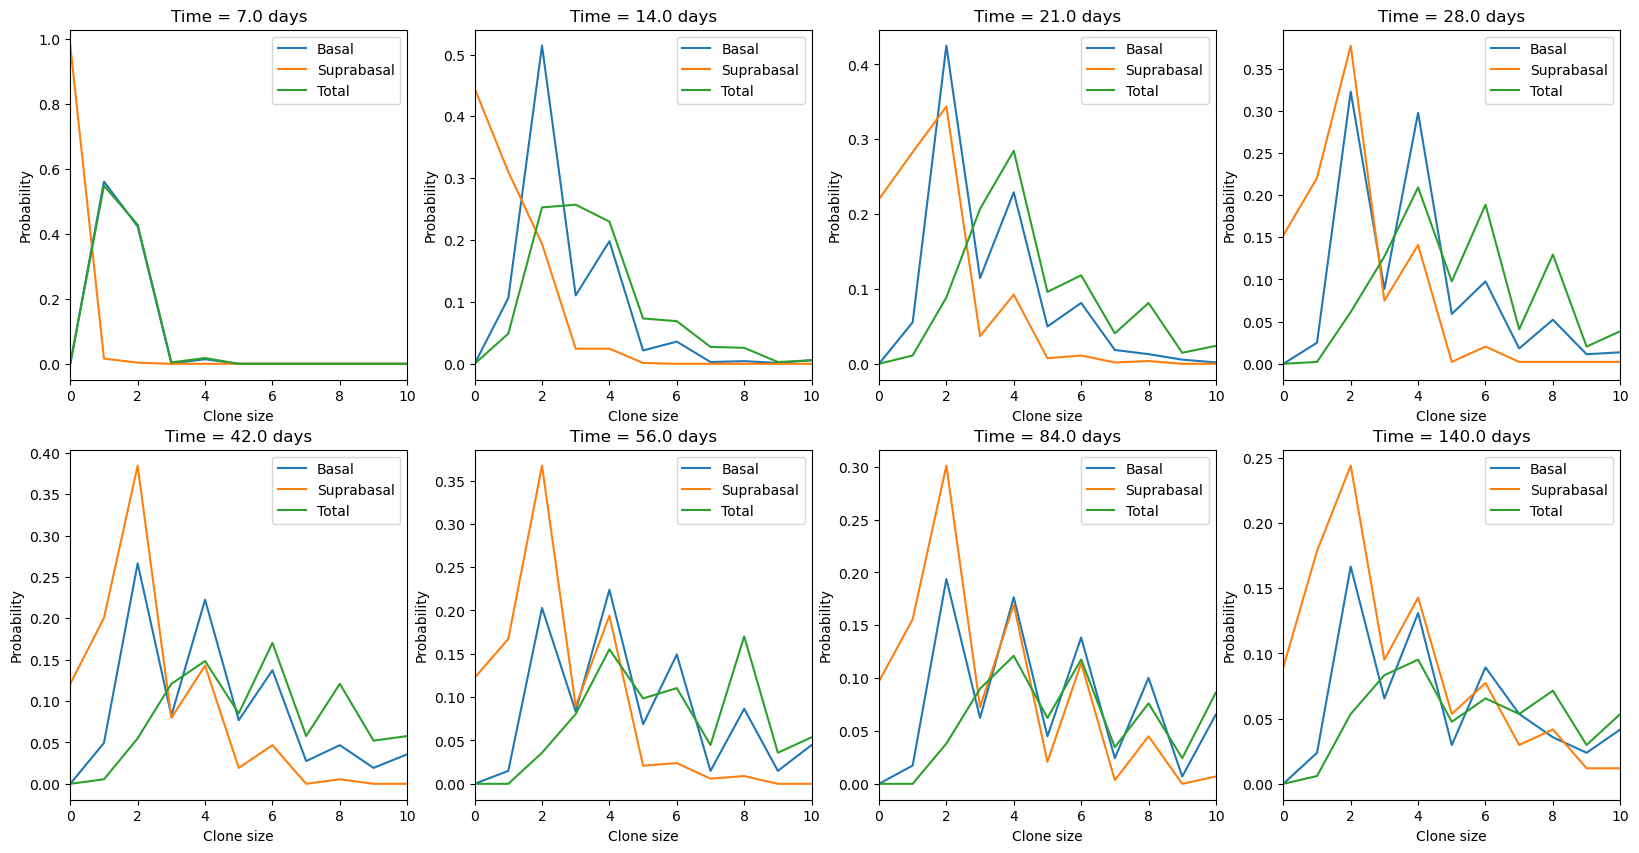

In [11]:
# Control data
filename = './241007_Control_homeo_fusedV4.csv'

miss_flag = -100

alldata = pd.read_csv(filename, sep=';')
alldata['sex'] = [m[0] for m in alldata['mice_ID'].values]
mice = list(alldata['mice_ID'].unique())
times = list(alldata['temps'].unique())
bas_names = ['D' + str(t) + '.basal' for t in times]
sup_names = ['D' + str(t) + '.supra' for t in times]
time_names = bas_names + sup_names
allclones = alldata['clone'].unique()

#Time-course data
full_timelapse = pd.DataFrame(columns = ['sex', 'mice_ID', 'clone', 'cat'] + time_names)

for c in allclones:
    clone_data = alldata.query('clone ==' + str(c)).copy()
    assert(len(clone_data['mice_ID'].unique()) == 1)
    #assert(len(clone_data['cat'].unique()) == 1)
    if len(clone_data['cat'].unique()) > 1:
        print('Error', c, clone_data['mice_ID'])
    clone_data.fillna(miss_flag, inplace=True)
    bas_data = {'D' + str(clone_data.temps.values[i]) + '.basal': int(clone_data.basal.values[i]) for i in range(len(clone_data))}
    sup_data = {'D' + str(clone_data.temps.values[i]) + '.supra': int(clone_data.supra.values[i]) for i in range(len(clone_data))}
    to_append = {'sex': clone_data['sex'].values[0], 'mice_ID': clone_data['mice_ID'].values[0], 'clone': c, 'cat': clone_data['cat'].values[0], **bas_data, **sup_data}
    full_timelapse = pd.concat([full_timelapse, pd.DataFrame([to_append])], ignore_index=True)

full_timelapse.fillna(miss_flag, inplace=True)

#Combined data
livesize = np.zeros((len(allclones), len(times), 2), dtype = 'int32')
livesize[:,:,0] = np.array(full_timelapse[bas_names].values, dtype = 'int32')
livesize[:,:,1] = np.array(full_timelapse[sup_names].values, dtype = 'int32')
lcs = clones.lanalysis(livesize, tvals = times, containsBasal = True)

full_timelapse.fillna(miss_flag, inplace=True)

all_moves, all_moves_bas = get_allmoves(livesize, full_timelapse, True)

data = {}
data['ctrBasalsize'] = lcs.av_bas_cs
data['ctrSuprasize'] = lcs.av_sup_cs
data['ctrTotalsize'] = lcs.av_tot_cs
data['ctrBasalEvenbias'] = lcs.ev_bas_cs
data['ctrSupraEvenbias'] = lcs.ev_sup_cs
data['ctrTotalEvenbias'] = lcs.ev_tot_cs

data['livesize'] = livesize
data['ctrjointpdf'] = lcs.joint_pdf

data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

data['all_moves'] = lcs.allmoves()
data['all_moves_bas'] = lcs.allmoves_bas()

data['ct_all_moves'] = all_moves
data['ct_all_moves_bas'] = all_moves_bas


cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

data['ctrpdf'] = cpdf

data['surprob'] = lcs.pers
data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
data['lcd']     = lcs.lcd
data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
data['nallc'] = lcs.non_missing
data['ctrNsamples'] = lcs.nsur

data['ctrTimeClonesize'] = lcs.tvals



save_object(data,    'data_ctr.pkl')
print('Saved to: ' + 'data_ctr.pkl')

plt.figure()
plt.errorbar(lcs.tvals[lcs.av_bas_cs > 0], lcs.av_bas_cs[lcs.av_bas_cs > 0], lcs.se_bas_cs[lcs.av_bas_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_sup_cs > 0], lcs.av_sup_cs[lcs.av_sup_cs > 0], lcs.se_sup_cs[lcs.av_sup_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_tot_cs > 0], lcs.av_tot_cs[lcs.av_tot_cs > 0], lcs.se_tot_cs[lcs.av_tot_cs > 0])    
plt.legend(['Basal', 'Suprabasal', 'Total'])
plt.xlabel('Time (days)')
plt.ylabel('Mean clone size')   
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.pers, np.sqrt(lcs.pers*(1-lcs.pers)/lcs.non_missing))
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.lcd, lcs1.se_bas_cs)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')
plt.show()

plt.figure()
plt.plot(lcs.tvals, lcs.ev_bas_cs, label = 'Basal')
plt.plot(lcs.tvals, lcs.ev_sup_cs, label = 'Suprabasal')
plt.plot(lcs.tvals, lcs.ev_tot_cs, label = 'Total')  
plt.legend()  
plt.xlabel('Time (days)')
plt.ylabel('Even bias')
plt.legend()
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(20, 10))

for t in range(len(lcs.tvals)):
    xx = t // 4
    yy = t % 4
    axs[xx,yy].plot(cpdf[t,:,:].T)
    axs[xx,yy].legend(['Basal', 'Suprabasal', 'Total'])
    axs[xx,yy].set_xlabel('Clone size')
    axs[xx,yy].set_ylabel('Probability')
    axs[xx,yy].set_xlim([0, 10])
    axs[xx,yy].set_title('Time = ' + str(lcs.tvals[t]) + ' days')
plt.show()

In [12]:
full_timelapse['max_tot'] = np.max(np.sum(livesize,2),1)
full_timelapse['ctype'] = ''
full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'

full_timelapse

,sex,mice_ID,clone,cat,D7.basal,D14.basal,D21.basal,D28.basal,D42.basal,D56.basal,...,D7.supra,D14.supra,D21.supra,D28.supra,D42.supra,D56.supra,D84.supra,D140.supra,max_tot,ctype
0,M,M30,30001,cherry,1,0,0,0,0,0,...,0,0,0,0,0,0,0,-100,1,D
1,M,M30,30002,GFP,2,0,0,0,0,0,...,0,1,0,0,0,0,0,-100,2,T
2,M,M30,30003,cherry,2,-100,-100,-100,-100,-100,...,0,-100,-100,-100,-100,-100,-100,-100,2,T
3,M,M30,30004,cherry,1,0,0,0,0,0,...,0,0,0,0,0,0,0,-100,1,D
4,M,M30,30005,CFP,1,4,-100,-100,-100,-100,...,0,0,-100,-100,-100,-100,-100,-100,4,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1166,F,F11,11105,cherry,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,D
1167,F,F11,11106,cherry,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,D
1168,F,F11,11107,cherry,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,D
1169,F,F11,11108,cherry,2,2,0,0,0,0,...,0,0,0,0,0,0,0,0,2,T


In [13]:
'''  
    Compute the counts tensor for experiments
'''

def extend_livesize(livesize):
    nclones = np.shape(livesize)[0]
    time0 = np.zeros((nclones, 1, 2), dtype = 'int32')
    time0[:,0,0] = 1
    return np.concatenate((time0, livesize), axis = 1)

full_timelapse['max_tot'] = np.max(np.sum(livesize,2),1)
full_timelapse['ctype'] = ''
full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'

full_livesize = extend_livesize(livesize)

ctypes = ['S', 'T', 'D']

ntimes = len(times)
ntypes  = len(ctypes)
nlayers = 2
max_bas = livesize[:,:,0].max() + 1
max_sup = livesize[:,:,1].max() + 1

''' 
    Define allmoves in the following way:
    allmoves[time, bas_t-1, sup_t-1, bast, bast, dSup2, mouse, clone type]
    
    We only specify moves starting from surviving clone numbers
    
    This is convenient for specifying likelihood
    
    Then we specify the unique transitions which occur in the data
'''
allmoves = np.zeros((len(times), max_bas, max_sup, max_bas, max_sup, ntypes, len(mice)), dtype = 'int32')

for m in range(len(mice)):
    for ct in range(len(ctypes)):
        cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
        for c in range(len(cids)):
            for t in range(ntimes):
                bas0 = full_livesize[cids[c],t,0]
                sup0 = full_livesize[cids[c],t,1]
                bas1 = full_livesize[cids[c],t+1,0]
                sup1 = full_livesize[cids[c],t+1,1]
                if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:
                    allmoves[t, bas0, sup0, bas1, sup1, ct, m] += 1
          
allmoves_bas = np.sum(allmoves, axis = (2,4))
                        
all_moves     = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'supra0', 'basal1', 'supra1', 'count'])
all_moves_bas = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'basal1', 'count'])

for m in range(len(mice)):
    for ct in [0]:
        cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
        for t in range(ntimes):
            unqclones = np.unique(full_livesize[cids,t:t+2,:], axis = 0)
            for u in unqclones:
                bas0 = u[0,0]
                sup0 = u[0,1]
                bas1 = u[1,0]
                sup1 = u[1,1]
                if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:                    
                    to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'supra0': sup0, 'basal1': bas1, 'supra1': sup1, 'count': allmoves[t, bas0, sup0, bas1, sup1, ct, m]}
                    all_moves = pd.concat([all_moves, pd.DataFrame([to_append])], ignore_index=True)  
                    
            unqbas = np.unique(full_livesize[cids,t:t+2,0], axis = 0)
            for u in unqbas:
                bas0 = u[0]
                bas1 = u[1]
                if bas0 > 0 and bas1 >= 0:                    
                    to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'basal1': bas1, 'count': allmoves_bas[t, bas0, bas1, ct, m]}
                    all_moves_bas = pd.concat([all_moves_bas, pd.DataFrame([to_append])], ignore_index=True)              


In [14]:
alldata['total'] = alldata['basal'] + alldata['supra']

surdata = alldata.copy()
surdata = surdata[~np.isnan(surdata['total'])]
surdata = surdata[surdata['basal'] > 0]
surdata = surdata.astype({'basal': 'int', 'supra': 'int', 'total': 'int'})

# average, sem, and number of clones for dataframe alldata
summary = surdata.groupby(['sex', 'mice_ID', 'temps']).agg({'basal': ['mean', 'sem', 'count'], 'supra': ['mean', 'sem', 'count'], 'total': ['mean', 'sem', 'count']})
summary

basal                     supra                  \
                       mean       sem count      mean       sem count   
sex mice_ID temps                                                       
F   F10     7      1.441860  0.043894   129  0.031008  0.015321   129   
            14     2.638889  0.202010    72  0.930556  0.084676    72   
            21     3.847458  0.364892    59  1.559322  0.162662    59   
            28     4.085106  0.338454    47  1.723404  0.179170    47   
            42     5.250000  0.586246    44  2.045455  0.217992    44   
...                     ...       ...   ...       ...       ...   ...   
M   M30     21     2.807692  0.350908    26  1.038462  0.179579    26   
            28     3.944444  0.702341    18  1.000000  0.180775    18   
            42     3.545455  0.867217    11  1.363636  0.152120    11   
            56     6.333333  1.185896    15  2.266667  0.472749    15   
            84     9.307692  1.638419    13  2.692308  0.682986    13   

                       total                  
                        mean       sem count  
sex mice_ID temps                             
F   F10     7       1.472868  0.044129   129  
            14      3.569444  0.202514    72  
            21      5.406780  0.458136    59  
            28      5.808511  0.423236    47  
            42      7.295455  0.706792    44  
...                      ...       ...   ...  
M   M30     21      3.846154  0.442692    26  
            28      4.944444  0.777428    18  
            42      4.909091  0.878579    11  
            56      8.600000  1.623635    15  
            84     12.000000  2.215910    13  

[78 rows x 9 columns]

-9 -9 [0 0 1 0 0 0 0]
-9 7 [0 0 1 0 0 0 0]
-8 -2 [0 0 0 0 1 0 0]
-8 0 [0 0 0 1 0 0 0]
-8 2 [0 0 0 0 0 1 0]
-8 6 [0 0 0 0 0 0 1]
-6 -2 [0 0 0 0 0 1 0]
-4 -8 [0 0 0 0 0 0 1]
-4 -4 [0 0 0 0 1 1 1]
-4 -2 [0 0 0 2 1 3 7]
-4 -1 [0 0 1 0 1 1 2]
-4 0 [0 3 1 1 3 4 4]
-4 1 [0 0 1 0 1 0 1]
-4 2 [0 0 0 0 2 0 0]
-4 4 [0 0 1 0 0 0 0]
-4 8 [0 0 0 0 0 0 1]
-3 -1 [0 0 0 1 0 1 1]
-3 0 [0 1 0 0 0 0 0]
-3 1 [0 0 0 2 0 0 0]
-3 2 [0 1 0 0 0 0 0]
-3 3 [0 1 1 0 0 0 0]
-3 6 [0 0 0 0 0 0 1]
-2 -4 [0 0 0 0 0 0 1]
-2 -3 [0 0 1 0 0 0 0]
-2 -2 [0 2 0 4 2 3 2]
-2 -1 [0 4 1 3 1 2 1]
-2 0 [0 5 9 5 6 5 2]
-2 1 [1 2 5 7 4 1 2]
-2 2 [ 1 13  8  7  3  1  0]
-2 3 [0 1 2 0 0 0 1]
-2 4 [1 6 1 3 0 0 0]
-1 -5 [0 0 0 1 0 0 0]
-1 -4 [0 0 0 0 1 0 0]
-1 -3 [0 0 0 0 0 0 1]
-1 -2 [0 0 0 1 0 0 1]
-1 -1 [0 0 2 1 0 1 1]
-1 0 [0 2 3 3 3 4 2]
-1 1 [1 3 3 1 0 0 0]
-1 2 [0 3 2 1 0 0 0]
-1 3 [0 1 1 1 0 0 0]
0 -5 [0 0 0 0 0 0 1]
0 -4 [0 0 1 0 0 1 0]
0 -3 [0 0 0 0 0 0 1]
0 -2 [ 0  1  5 10  6  1  0]
0 -1 [0 3 2 1 2 1 0]
0 1 [0 9 4 4 0 2 0]
0 2 

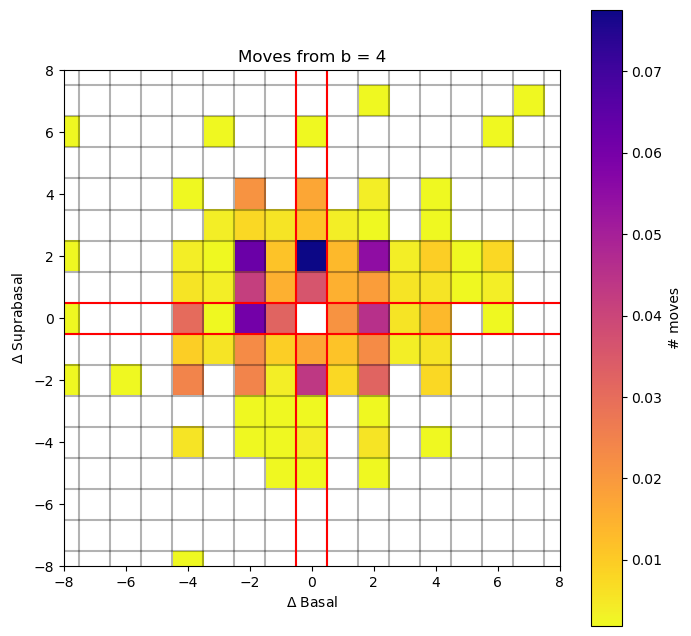

In [15]:

def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, tstart = 0, plot = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'Moves from b = ' + str(init_bas)
    elif init_bas is None and init_sup is not None:
        tit = 'Moves from b = ' + str(init_sup)
    elif init_bas is not None and init_sup is not None:
        tit = 'Moves from (b,s) = (' + str(init_bas) + ',' + str(init_sup) + ')'
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 50] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                print(mb,ms, allmoves[:,mb,ms])


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        plt.figure(figsize=(8,8))
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], origin='lower', cmap = 'plasma_r')
        plt.xlabel(r'$\Delta$ Basal')
        plt.ylabel(r'$\Delta$ Suprabasal')
        if use_log:
            plt.colorbar(label = 'log2(# moves)')
        else:
            plt.colorbar(label = '# moves')
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,2))
        plt.yticks(np.arange(-max_move,max_move+1,2))
        plt.title(tit)
        #plt.axis('square')
        plt.show()
    
    return allmoves
    
allmoves = plot_moves(livesize, init_bas = 4, init_sup = None, normalise=True, max_move = 8, plot = True)

/tmp/ipykernel_176186/3343903776.py:28: RuntimeWarning: invalid value encountered in divide
  frac_even_move[i-1,:] = (even_change - odd_change)/(even_change + odd_change)


Text(0.5, 1.0, 'Bias of moves to even basal #')

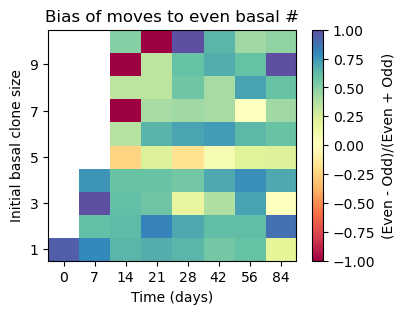

In [16]:
def even_from_state(livesize, init_bas = 1, init_sup = None, max_move = 10, tstart = 0, N = 10):
    full_livesize = np.zeros((livesize.shape[0], livesize.shape[1] + 1, 2), dtype = 'int32')
    full_livesize[:,0,0] = 1
    full_livesize[:,1:,:] = livesize.copy()

    moves = full_livesize[:,tstart+1:,0:3] - full_livesize[:,tstart:-1,0:3] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]

    N = 10
    frac_even_move = np.zeros((N,ntimes))

    for i in range(1,N+1):
        init_bas = i
        moves[np.abs(moves) > 50] = -max_move
        changing = np.sum(np.abs(moves),2) > 0
        if init_bas is None and init_sup is None:
            mask = 1
        elif init_bas is not None and init_sup is None:
            mask = full_livesize[:,tstart:-1,0] == init_bas
        elif init_bas is None and init_sup is not None:
            mask = full_livesize[:,tstart:-1,1] == init_sup
        elif init_bas is not None and init_sup is not None:
            mask = (full_livesize[:,tstart:-1,0] == init_bas) & (full_livesize[:,tstart:-1,1] == init_sup)
            
        even_change = np.sum(((moves[:,:,0] % 2) == 0)*changing*mask,0)
        odd_change  = np.sum(((moves[:,:,0] % 2) == 1)*changing*mask,0)

        frac_even_move[i-1,:] = (even_change - odd_change)/(even_change + odd_change)
        
    return frac_even_move


frac_even_move = even_from_state(livesize, init_bas = 1, init_sup = None, N = 10)
ntimes = np.shape(frac_even_move)[1]
N = np.shape(frac_even_move)[0]
tc = np.array([0] + times)

plt.figure()
plt.imshow(frac_even_move*(-1)**(np.arange(1,N+1)[:,None] % 2), aspect = 'auto', cmap = 'Spectral', extent = [0,ntimes,0.5,N+0.5], origin='lower')
plt.xticks(np.arange(ntimes) + 0.5, labels=tc[:-1])
plt.yticks(np.arange(1,N,2))
plt.colorbar(label = '(Even - Odd)/(Even + Odd)')
plt.xlabel('Time (days)')
plt.ylabel('Initial basal clone size')
plt.title('Bias of moves to even basal #')

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_ctr_M30.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_ctr_M1.pkl


/home/joelh/Documents/Science/Projects/GlassyTissue/papers/StemTA_Homeostasis/squasim-homeostasis/experiment/homeo/../../analysis/clones.py:543: RuntimeWarning: invalid value encountered in divide
  self._av_bas_cs = np.sum(self.bas_ls*(self.bas_ls > 0),0)/self.nsur
/home/joelh/Documents/Science/Projects/GlassyTissue/papers/StemTA_Homeostasis/squasim-homeostasis/experiment/homeo/../../analysis/clones.py:587: RuntimeWarning: invalid value encountered in divide
  self._av_sup_cs = np.sum(self.sup_ls*bas_mask*(self.sup_ls >= 0),0)/self.nsur
/home/joelh/Documents/Science/Projects/GlassyTissue/papers/StemTA_Homeostasis/squasim-homeostasis/experiment/homeo/../../analysis/clones.py:572: RuntimeWarning: invalid value encountered in divide
  self._av_tot_cs = np.sum(self.tot_ls*bas_mask*(self.tot_ls >= 0),0)/self.nsur
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=d

...

Saved to: data_ctr_M1bis.pkl
Saved to: data_ctr_F3.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_ctr_F4.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_ctr_F11.pkl


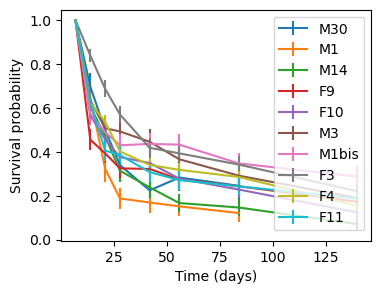

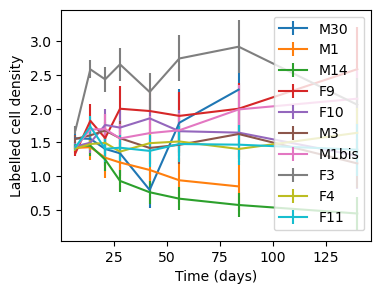

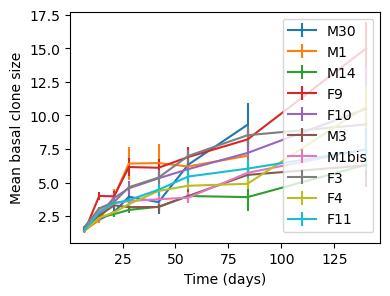

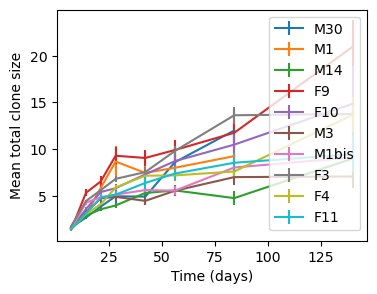

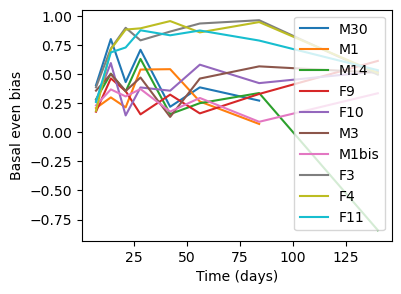

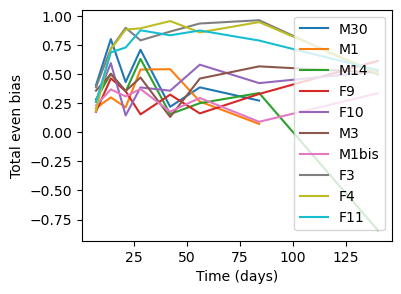

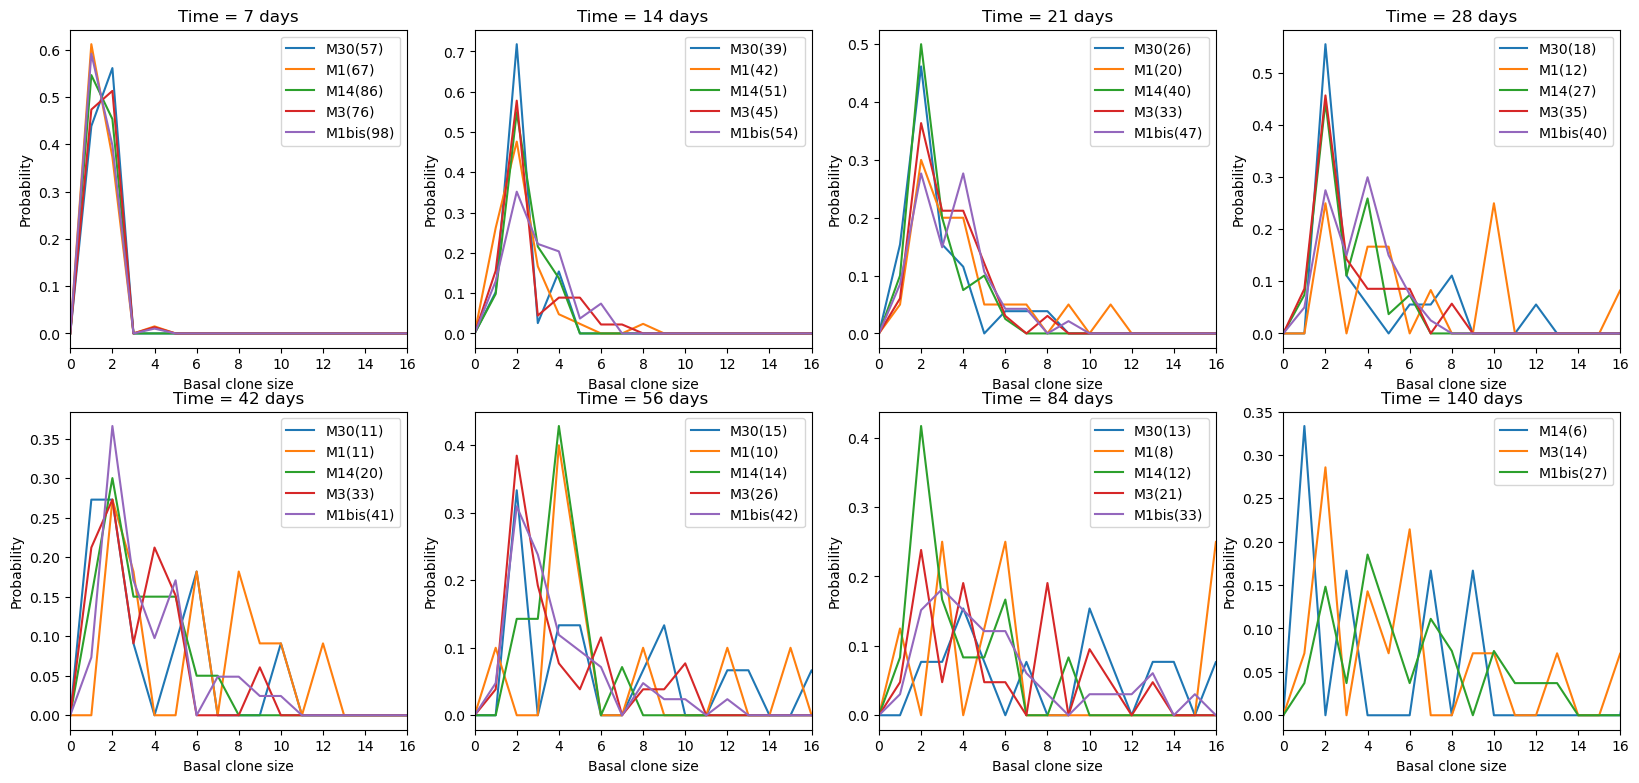

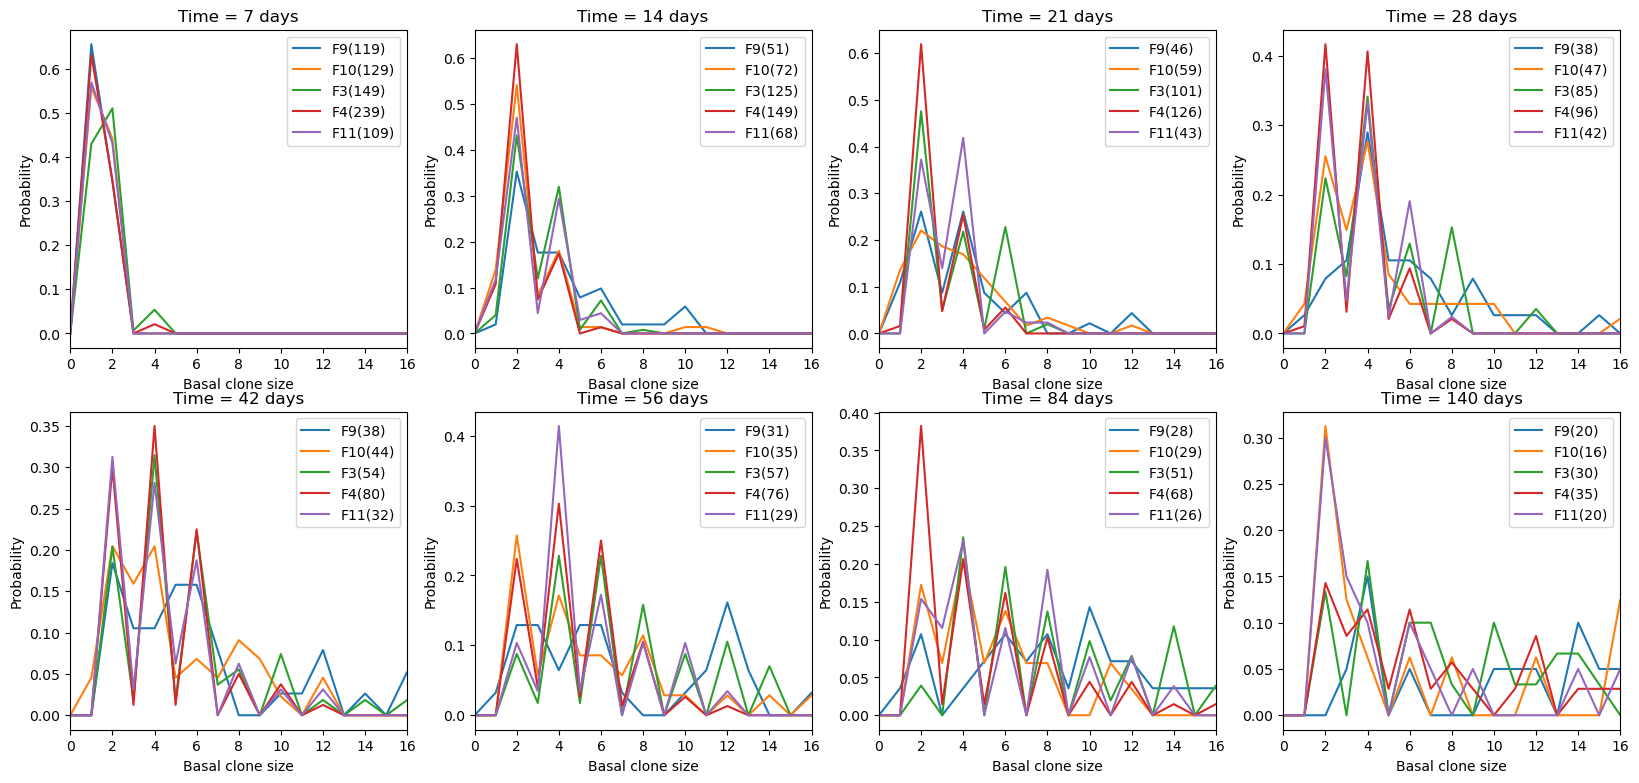

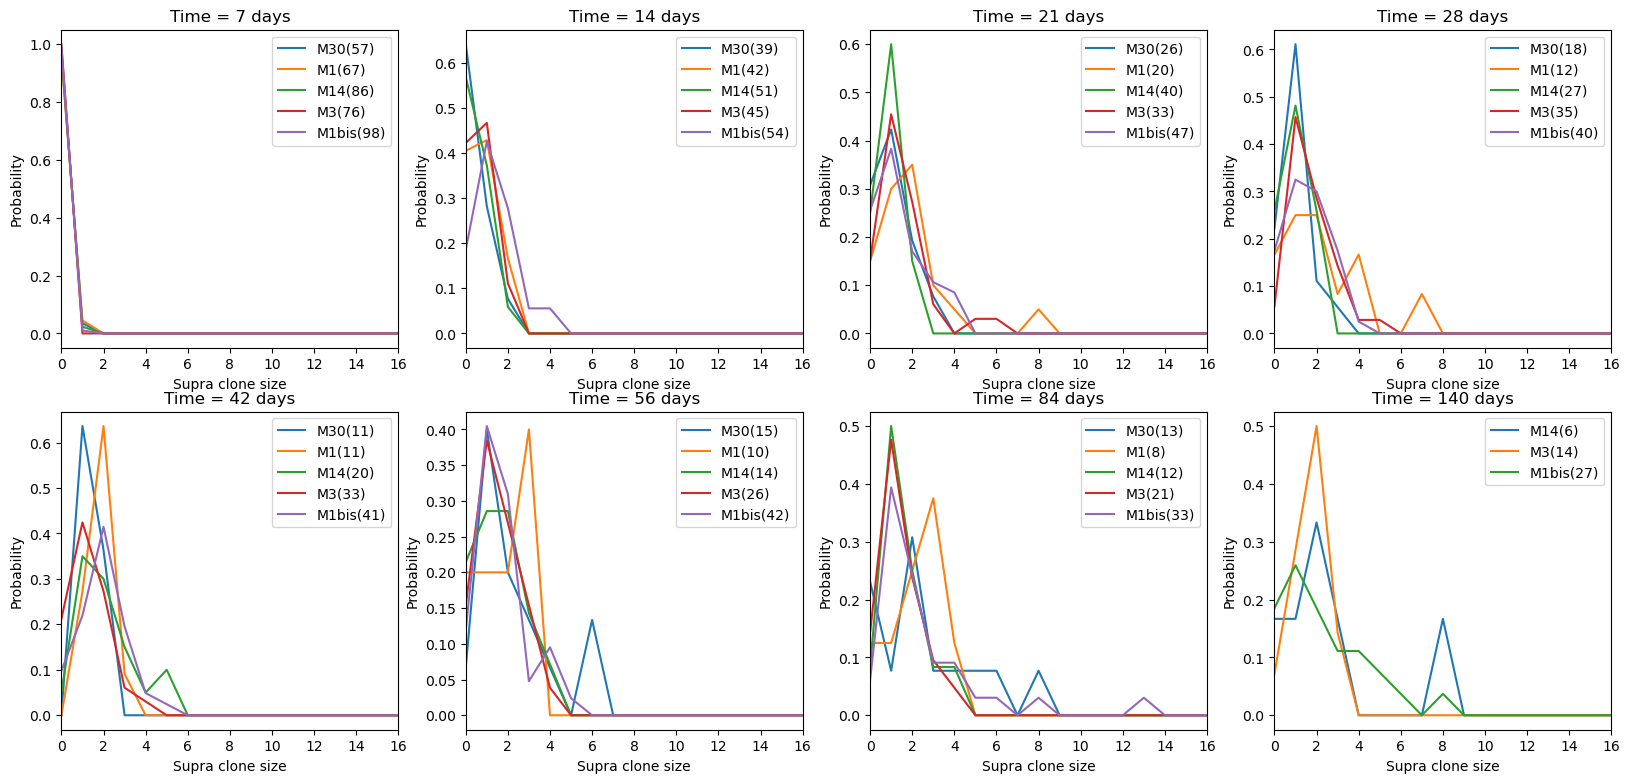

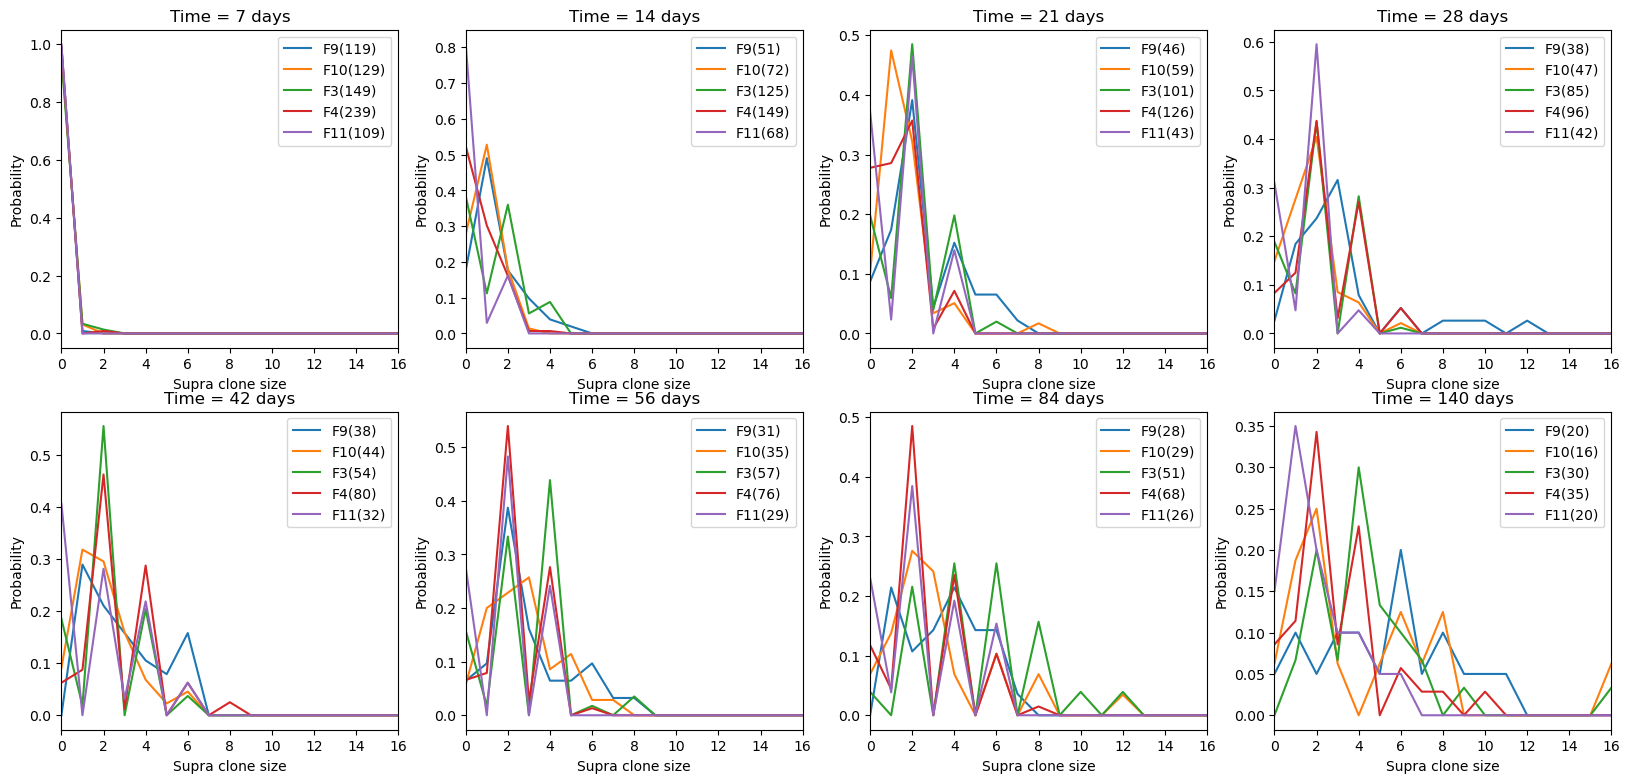

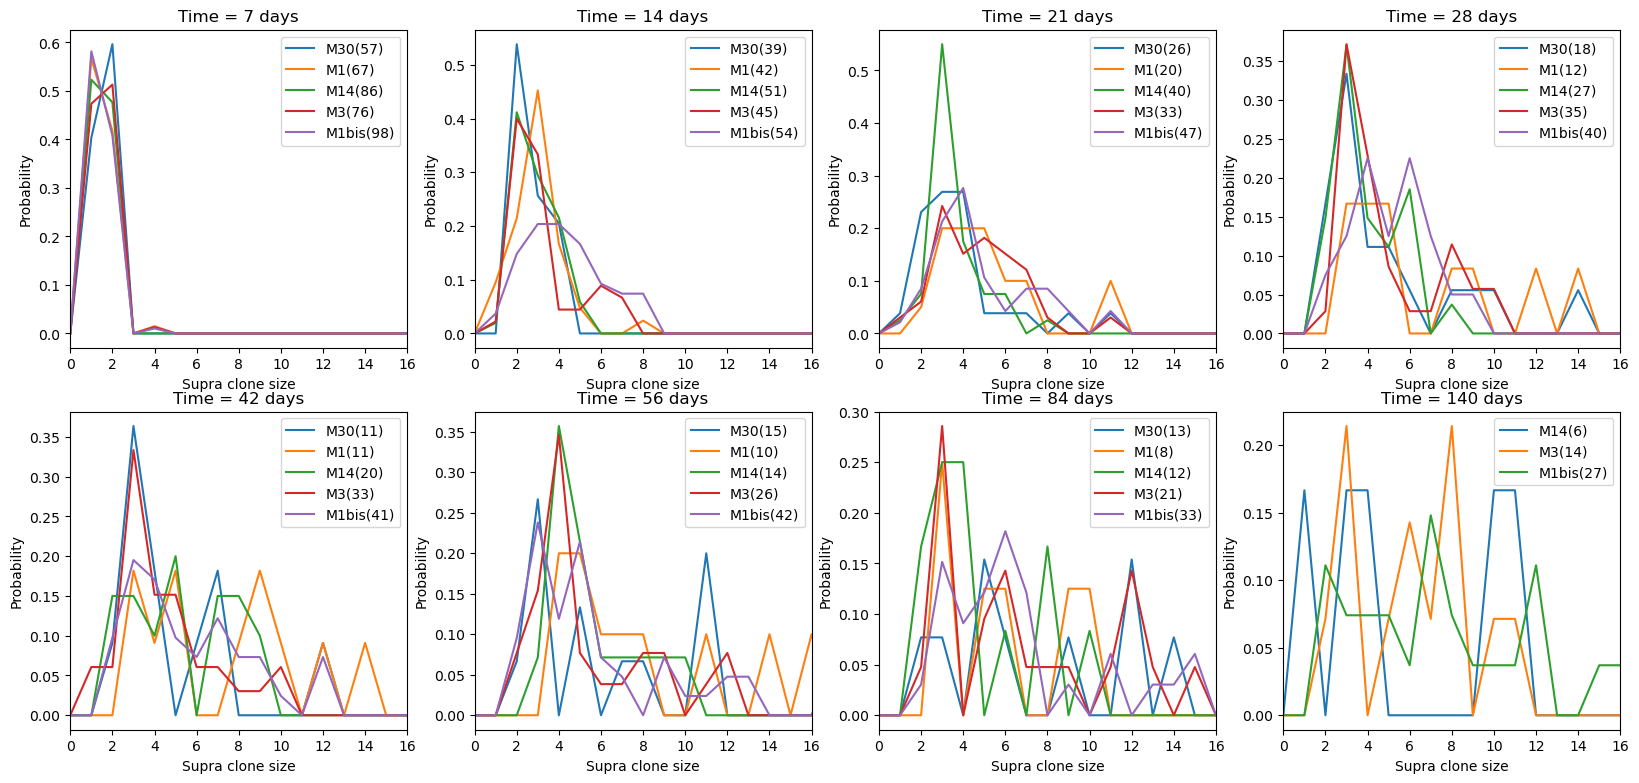

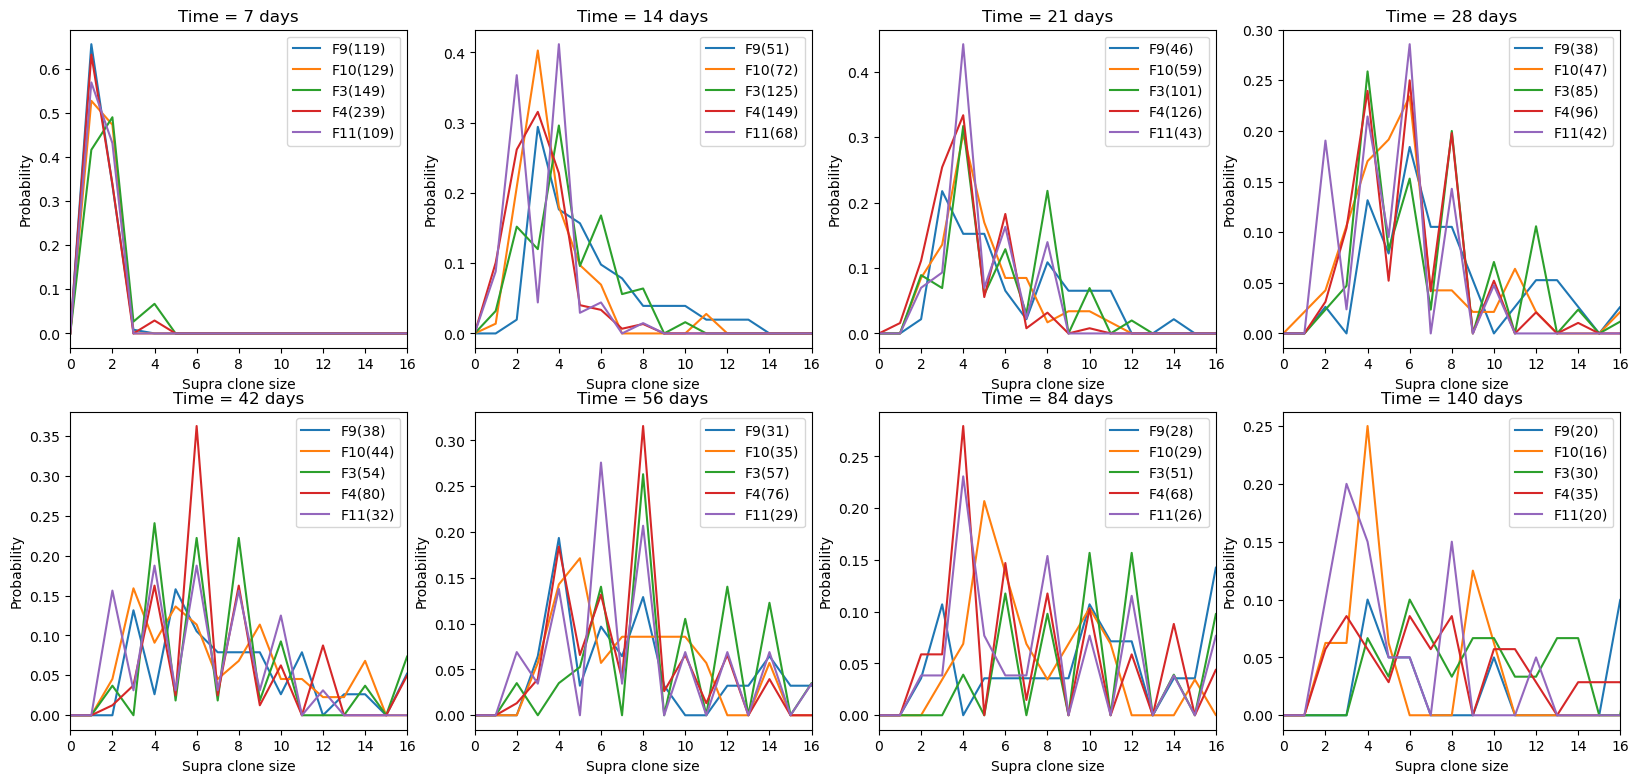

In [17]:
#Mouse-by-mouse data

for mid in mice:        
    sub_timelapse = full_timelapse[full_timelapse['mice_ID'] == mid]
    livesize = np.zeros((len(sub_timelapse), len(times), 2), dtype = 'int32')
    livesize[:,:,0] = np.array(sub_timelapse[bas_names].values, dtype = 'int32')
    livesize[:,:,1] = np.array(sub_timelapse[sup_names].values, dtype = 'int32')
    
    inctimes = np.max(np.min(livesize,2),0) >= 0
    livesize = livesize[:, inctimes, :]
    lcs = clones.lanalysis(livesize, tvals = np.array(times)[inctimes], containsBasal = True)


    data = {}
    data['ctrBasalsize'] = lcs.av_bas_cs
    data['ctrSuprasize'] = lcs.av_sup_cs
    data['ctrTotalsize'] = lcs.av_tot_cs
    data['ctrBasalEvenbias'] = lcs.ev_bas_cs
    data['ctrSupraEvenbias'] = lcs.ev_sup_cs
    data['ctrTotalEvenbias'] = lcs.ev_tot_cs

    data['livesize'] = livesize
    data['ctrjointpdf'] = lcs.joint_pdf

    data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
    data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
    data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
    data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
    data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
    data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

    data['all_moves'] = lcs.allmoves()
    data['all_moves_bas'] = lcs.allmoves_bas()

    cpdf = np.zeros((np.sum(inctimes), 3, np.max(lcs.tot_ls) + 2))
    cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
    cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
    cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

    data['ctrpdf'] = cpdf

    data['surprob'] = lcs.pers
    data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


    lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
    data['lcd']     = lcs.lcd
    data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
    data['nallc'] = lcs.non_missing
    data['ctrNsamples'] = lcs.nsur

    data['ctrTimeClonesize'] = lcs.tvals

    save_object(data,    'data_ctr_' + mid + '.pkl')
    print('Saved to: ' + 'data_ctr_' + mid + '.pkl')

ct = 'ctr'
plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']
    lcd        = exp_data['lcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']


    plt.errorbar(te, surprob, np.sqrt(surprob*(1-surprob)/N), label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')   
plt.legend()
plt.show()


plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    lcd_se     = exp_data['SDlcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']
    data['ctrNsamples'] = lcs.nsur 

    plt.errorbar(te, lcd, lcd_se, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean basal clone size')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrTotalsize']
    se_bas_ctr = exp_data['ctrSDTotalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean total clone size')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_bas_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Basal even bias')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_bas_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Total even bias')   
plt.legend()
plt.show()        
    

for sex in ['M', 'F']:
    fmt = '-'   
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data_' + ct + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue
            
        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,0,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Basal clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()      

for sex in ['M', 'F']:
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data_' + ct + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue

        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,1,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Supra clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()    

for sex in ['M', 'F']:
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data_' + ct + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue  

        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,2,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Supra clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()   
        

Repairing basal CS mistakes for [229 253]
[[[0 5 6 4 3 5 4 5]
  [1 1 3 4 2 3 1 2]]

 [[1 0 0 0 1 0 0 0]
  [0 0 0 0 0 0 0 0]]]
Repairing total CS mistakes for [253]
[[[   1    0    0 -100    1    0    0    0]
  [   0    0    0 -100    0    0    0    0]]]


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Repairing basal CS mistakes for [229 253]
[[[0 5 6 4 3 5 4 5]
  [1 1 3 4 2 3 1 2]]

 [[1 0 0 0 1 0 0 0]
  [0 0 0 0 0 0 0 0]]]
Repairing total CS mistakes for [253]
[[[   1    0    0 -100    1    0    0    0]
  [   0    0    0 -100    0    0    0    0]]]
Saved to: data_ctr_M.pkl
Repairing total CS mistakes for [219]
[[[2 4 1 0 0 0 0 0]
  [0 2 2 1 0 4 0 0]]]
Repairing total CS mistakes for [219]
[[[2 4 1 0 0 0 0 0]
  [0 2 2 1 0 4 0 0]]]
Saved to: data_ctr_F.pkl


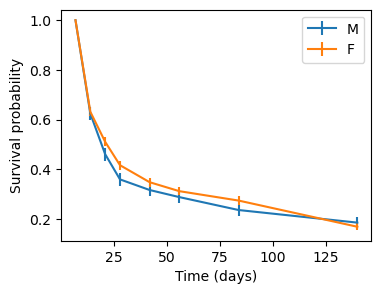

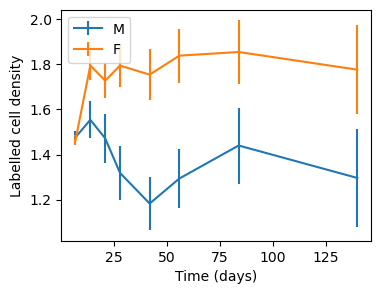

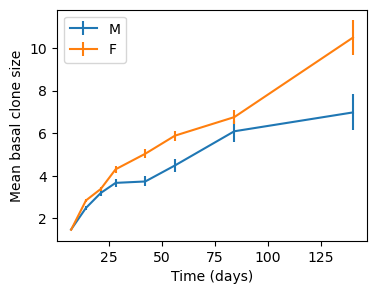

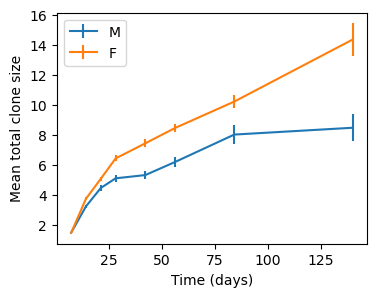

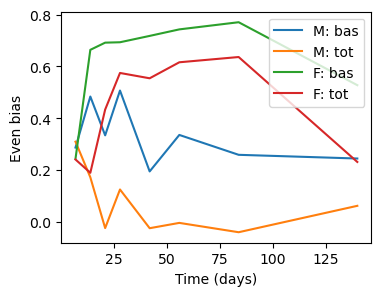

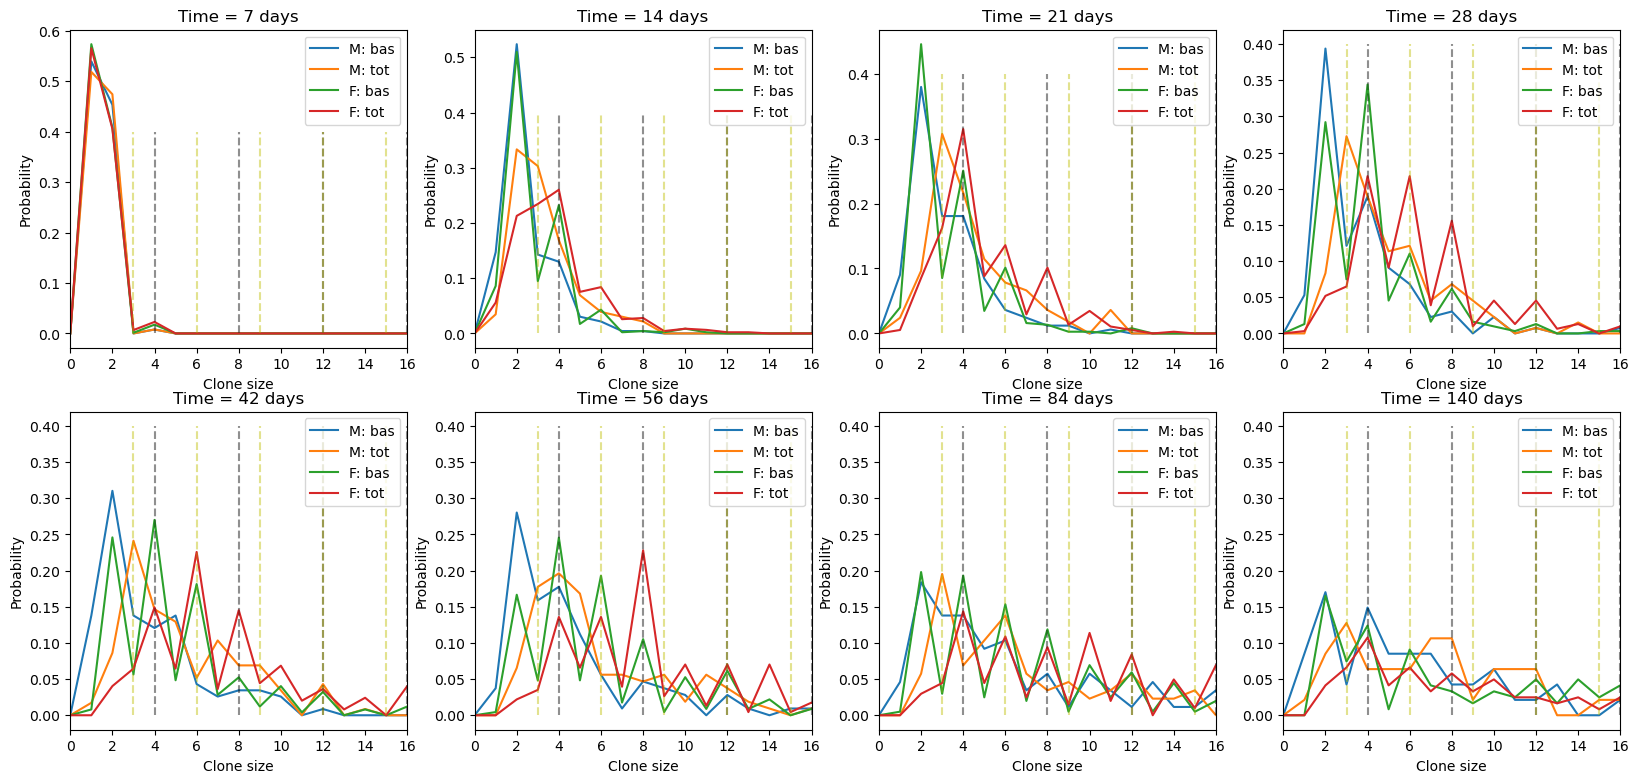

In [18]:
#Data by sex
sexes = ['M', 'F']

for sex in sexes:        
    sub_timelapse = full_timelapse[full_timelapse['sex'] == sex]
    livesize = np.zeros((len(sub_timelapse), len(times), 2), dtype = 'int32')
    livesize[:,:,0] = np.array(sub_timelapse[bas_names].values, dtype = 'int32')
    livesize[:,:,1] = np.array(sub_timelapse[sup_names].values, dtype = 'int32')
    
    inctimes = np.max(np.min(livesize,2),0) >= 0
    livesize = livesize[:, inctimes, :]
    lcs = clones.lanalysis(livesize, tvals = np.array(times)[inctimes], containsBasal = True)

    data = {}
    data['ctrBasalsize'] = lcs.av_bas_cs
    data['ctrSuprasize'] = lcs.av_sup_cs
    data['ctrTotalsize'] = lcs.av_tot_cs
    data['ctrBasalEvenbias'] = lcs.ev_bas_cs
    data['ctrSupraEvenbias'] = lcs.ev_sup_cs
    data['ctrTotalEvenbias'] = lcs.ev_tot_cs

    data['livesize'] = livesize
    data['ctrjointpdf'] = lcs.joint_pdf

    data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
    data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
    data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
    data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
    data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
    data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

    data['all_moves'] = lcs.allmoves()
    data['all_moves_bas'] = lcs.allmoves_bas()


    cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
    cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
    cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
    cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

    data['ctrpdf'] = cpdf

    data['surprob'] = lcs.pers
    data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


    lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
    data['lcd']     = lcs.lcd
    data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
    data['nallc'] = lcs.non_missing
    data['ctrNsamples'] = lcs.nsur

    data['ctrTimeClonesize'] = lcs.tvals

    save_object(data,    'data_ctr_' + sex + '.pkl')
    print('Saved to: ' + 'data_ctr_' + sex + '.pkl')

ct = 'ctr'
plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']
    lcd        = exp_data['lcd']
    N = exp_data['nallc']  
    tvals = exp_data['ctrTimeClonesize'] 

    plt.errorbar(tvals, surprob, np.sqrt(surprob*(1-surprob)/N), label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')   
plt.legend()
plt.show()


plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    lcd_se     = exp_data['SDlcd']
    N = exp_data['nallc']  
    tvals = exp_data['ctrTimeClonesize']      

    plt.errorbar(tvals, lcd, lcd_se, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')   
plt.legend()
plt.show()

plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']          

    plt.errorbar(tvals, av_bas_ctr, se_bas_ctr, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Mean basal clone size')   
plt.legend()
plt.show()

plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_tot_ctr = exp_data['ctrTotalsize']
    se_tot_ctr = exp_data['ctrSDTotalsize']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']      

    plt.errorbar(tvals, av_tot_ctr, se_tot_ctr, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Mean total clone size')   
plt.legend()
plt.show()

plt.figure()

for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']          

    plt.plot(np.array(tvals), ev_bas_ctr, label = sex + ': bas')
    plt.plot(np.array(tvals), ev_tot_ctr, label = sex + ': tot')  
plt.legend()  
plt.xlabel('Time (days)')
plt.ylabel('Even bias')
plt.legend()
plt.show()


fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']

    for t in range(cpdf.shape[0]):
        xx = t // 4
        yy = t % 4
        axs[xx,yy].plot(cpdf[t,np.array([0,2]),:].T)
        axs[xx,yy].legend(['M: bas', 'M: tot', 'F: bas', 'F: tot'])
        axs[xx,yy].set_xlabel('Clone size')
        axs[xx,yy].set_ylabel('Probability')
        axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
        axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
        axs[xx,yy].set_xlim([0, 16])
        axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
plt.show()      
    